# Tarea · Diagnóstico de cáncer de mama con cinco clasificadores
### Regresión logística · Naïve Bayes · SVM · Árbol de decisión · Random Forest

**FP13 · Inteligencia Artificial** — Universidad Autónoma de Guadalajara / Leonardo Velasco Alvarez

**Unidad 5:** 5.1 Clasificación · 5.2 Aprendizaje supervisado · 5.3 Preprocesamiento · 5.4 Codificación de etiquetas · 5.5 Regresión logística · 5.6 Naïve Bayes · 5.7 Matrices de confusión · 5.8 SVM
**Unidad 6:** 6.1 Árboles de decisión · 6.3 Bosques aleatorios · 6.5 Búsqueda de rejilla

---

### 🏥 El problema clínico
Cuando se detecta una masa en la mama, una forma rápida y poco invasiva de estudiarla es la **biopsia por aspiración con aguja fina (BAAF)**: con una aguja delgada se extraen células, se tiñen y se observan al microscopio. En la Universidad de Wisconsin se digitalizaron esas imágenes y se midieron los **núcleos de las células** (tamaño, forma, textura…).

Un servicio de patología quiere una herramienta de **apoyo** que, con esas 30 mediciones, indique si el tumor **probablemente es maligno** para priorizar el caso.

> ⚠️ Un **falso negativo** (decir *benigno* a un tumor *maligno*) significa que una paciente con cáncer se va a casa sin tratamiento. Por eso, en esta tarea **la exactitud no basta**: buscaremos modelos que **casi no dejen escapar tumores malignos**.

### 📋 Instrucciones
1. Trabaja en tu entorno de github (VS Code) y ejecuta las celdas **en orden**, de arriba hacia abajo.
2. Cada `____` es un hueco que debes completar. Las líneas con huecos están marcadas con ✏️. **No modifiques el resto del código.**
3. Si una celda marca error, revisa los huecos de esa celda y de las anteriores.
4. Al final responde la **reflexión** en las celdas marcadas con ✍️.

### 🧮 Puntuación
| Sección | Puntos |
|---|:---:|
| 1–3 · Carga, exploración y preprocesamiento | 15 |
| 4–8 · Cinco modelos con búsqueda de rejilla (9 c/u) | 45 |
| 9–10 · Comparación final y ajuste del umbral | 10 |
| 11 · Reflexión: ¿cuál es el mejor modelo? | 30 |
| **Total** | **100** |

### ¿Qué cambia respecto a la práctica de clase?
- La etiqueta viene como **texto** (`M` / `B`) → usaremos **`LabelEncoder`** (tema 5.4).
- Hiperparámetros nuevos: kernel `"poly"` con `degree` (SVM), `min_samples_split` (árbol), `max_features="log2"` y `min_samples_leaf` (bosque), y `np.logspace` para generar los valores de `var_smoothing` (Naïve Bayes).

---
## 0 · Librerías

In [1]:
# Importando librerías
import warnings
warnings.filterwarnings("ignore")      # oculta avisos técnicos para que la pantalla quede limpia

import numpy as np                     # cálculo numérico
import pandas as pd                    # tablas de datos
import matplotlib.pyplot as plt        # gráficas

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix

---
## 1 · Los datos  *(5 puntos)*

**Breast Cancer Wisconsin (Diagnostic)** — UCI Machine Learning, publicado en Kaggle como `uciml/breast-cancer-wisconsin-data`. El archivo dentro del dataset se llama **`data.csv`**.

569 pacientes. A cada núcleo celular se le midieron **10 características**:

| Grupo | Variables | ¿Qué describe? |
|---|---|---|
| Tamaño | `radius`, `perimeter`, `area` | Qué tan grande es el núcleo |
| Textura | `texture`, `smoothness` | Variación de tonos de gris · qué tan lisa es la orilla |
| Forma | `compactness`, `concavity`, `concave points`, `symmetry`, `fractal_dimension` | Qué tan irregular o "hundido" es el contorno |

Cada característica aparece **3 veces**: `_mean` (promedio de los núcleos), `_se` (error estándar) y `_worst` (promedio de los 3 núcleos más grandes/anormales) → **30 variables**.

La columna **`diagnosis`** es lo que queremos predecir: **`M` = maligno**, **`B` = benigno**.

In [2]:
# Importando datos desde Kaggle
import kagglehub
from kagglehub import KaggleDatasetAdapter

df = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS,
                            "uciml/breast-cancer-wisconsin-data",
                            "data.csv")

100%|██████████| 122k/122k [00:00<00:00, 1.04MB/s]


In [3]:
# Explorando las primeras filas
df.head()    # ✏️

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
# Imprimiendo renglones y columnas del dataframe
df.shape

(569, 33)

---
## 2 · Exploración  *(4 puntos)*

In [5]:
# Comprobando si existen datos nulos
df.isnull().sum()    # ✏️

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

Observa la última columna, **`Unnamed: 32`**: ¡está vacía en los 569 renglones! Aparece porque el archivo CSV trae una coma de más al final de cada línea. No aporta nada, así que la eliminaremos junto con **`id`** (un número de expediente no ayuda a diagnosticar).

In [6]:
# Proporción de cada diagnóstico
df['diagnosis'].value_counts(normalize=True)    # ✏️

diagnosis
B    0.627417
M    0.372583
Name: proportion, dtype: float64

In [7]:
# Comparando la escala de tres variables
df[['area_mean', 'radius_mean', 'smoothness_mean']].describe().T

,count,mean,std,min,25%,50%,75%,max
area_mean,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
radius_mean,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
smoothness_mean,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634


`area_mean` llega a **~2,500**, mientras que `smoothness_mean` no pasa de **0.17**. La regresión logística y la SVM comparan variables con coeficientes y distancias, así que necesitan que todas estén en la **misma escala** → `StandardScaler` (tema 5.3). Los árboles no: solo preguntan *"¿es mayor que…?"*.

---
## 3 · Preprocesamiento y codificación de etiquetas  *(6 puntos)*

1. **Eliminar** las columnas que no sirven para predecir (`id`, `Unnamed: 32`).
2. **Codificar la etiqueta** con `LabelEncoder`: los modelos solo entienden números.
3. **Separar** `X` (las 30 mediciones) de `y` (el diagnóstico).
4. **Dividir** en entrenamiento y prueba conservando la proporción de malignos (`stratify`).

In [8]:
# Eliminando las columnas que no sirven para predecir
df = df.drop(columns=['id', 'Unnamed: 32'])    # ✏️
df.shape

(569, 31)

In [9]:
# Codificando la etiqueta: texto → número
codificador = LabelEncoder()
df['diagnosis'] = codificador.fit_transform(df['diagnosis'])    # ✏️

# ¿Qué número recibió cada letra?
print(codificador.classes_)          # posición 0 → primera letra, posición 1 → segunda letra
df['diagnosis'].value_counts()

['B' 'M']


diagnosis
0    357
1    212
Name: count, dtype: int64

`LabelEncoder` asigna los números en **orden alfabético**: **B → 0** y **M → 1**. ¡Justo lo que queremos! La clase **positiva (1)** es la que buscamos detectar: **maligno**. Así, `recall` medirá exactamente *"de cada 100 tumores malignos, ¿cuántos detecta el modelo?"*.

> ¿Por qué `LabelEncoder` y no one-hot? Porque es la **variable objetivo**: una sola columna con dos categorías. El one-hot se usa para variables de **entrada** con texto.

In [10]:
# Separando X (mediciones) de y (diagnóstico)
y = df['diagnosis']    # ✏️
X = df.drop(columns=['diagnosis'])

print(X.shape, y.shape)

(569, 30) (569,)


In [11]:
# Dividiendo en entrenamiento (80 %) y prueba (20 %), conservando la proporción B/M
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20,
                                                    stratify=y, random_state=42)    # ✏️

print(f'Dimensiones de entrenamiento: {X_train.shape}')
print(f'Dimensiones de prueba:        {X_test.shape}')
print(f'Tumores malignos en prueba:   {y_test.sum()}')

Dimensiones de entrenamiento: (455, 30)
Dimensiones de prueba:        (114, 30)
Tumores malignos en prueba:   42


---
## 4 · ¿Cómo vamos a evaluar?

Las filas son la **realidad** y las columnas lo que **predice** el modelo:

| | Predice **Benigno** | Predice **Maligno** |
|---|:---:|:---:|
| **Realmente benigno** | ✅ VN · benigno bien descartado | ⚠️ FP · falsa alarma (estudios de más) |
| **Realmente maligno** | ❌ **FN · cáncer que se va a casa** | ✅ VP · cáncer detectado |

<br>

| Métrica | Pregunta clínica que responde |
|---|---|
| **Exactitud** (`accuracy`) | De cada 100 pacientes, ¿cuántas clasifica bien? |
| **Precisión** (`precision`) | Cuando dice "maligno", ¿cuántas veces acierta? |
| **Sensibilidad** (`recall`) | De cada 100 tumores malignos, ¿cuántos detecta? |
| **Especificidad** | De cada 100 tumores benignos, ¿cuántos descarta bien? |

**Regla de esta tarea:** cada modelo se optimiza con 3 métricas distintas (`accuracy`, `precision` y `recall`). De esas 3 versiones, guardaremos como **finalista** la optimizada con **`recall`** (sensibilidad), porque es la que busca dejar escapar el menor número de tumores malignos (FN).

In [12]:
# Nombres de las clases (0 y 1 respectivamente)
clases = ['Benigno', 'Maligno']

# Métricas con las que vamos a optimizar cada modelo
metricas = ['accuracy', 'precision', 'recall']

# Aquí guardaremos el modelo finalista de cada algoritmo
finalistas = {}

---
## 5 · Regresión logística  *(9 puntos)*

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`C`** | Inverso de la regularización: `C` pequeño = modelo más simple y "prudente" | 0.01 · 0.1 · 1 · 10 · 100 |
| **`l1_ratio`** | Tipo de regularización: 0 = L2 · 1 = L1 (puede apagar variables) · 0.5 = mezcla | 0 · 0.5 · 1 |
| **`class_weight`** | `"balanced"` le da más peso a la clase con menos pacientes (malignos) | `None` · `"balanced"` |

In [13]:
# Importando el modelo
from sklearn.linear_model import LogisticRegression

# Pipeline: escalar → modelo
reglog_base = Pipeline([
    ("escalar", StandardScaler()),    # ✏️
    ("modelo",  LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0,    # ✏️
                                   max_iter=5000, random_state=42))
])

# Ajustando el modelo con valores por defecto
reglog_base.fit(X_train, y_train)    # ✏️

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


              precision    recall  f1-score   support

     Benigno       0.96      0.99      0.97        72
     Maligno       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



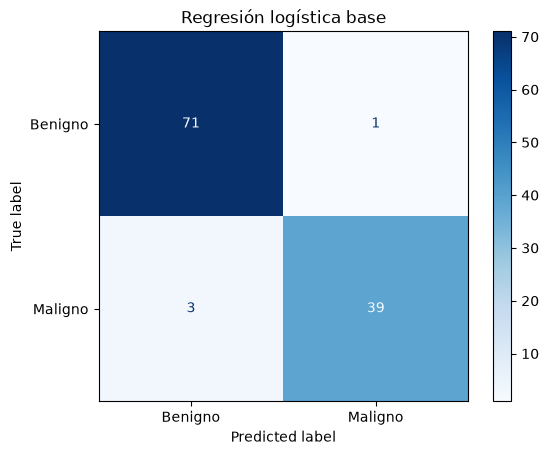

In [14]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = reglog_base.predict(X_test)    # ✏️

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')
plt.title('Regresión logística base')
plt.show()

In [ ]:
# Hiperparámetros a optimizar
rejilla_reglog = {
    "modelo__C":            [0.01, 0.1, 1, 10, 100],
    "modelo__l1_ratio":     [0, 0.5, 1],             # 0 = L2 · 0.5 = mezcla · 1 = L1  ✏️
    "modelo__class_weight": [None, "balanced"],    # ✏️
}
# 5 × 3 × 2 = 30 combinaciones

In [16]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(reglog_base, rejilla_reglog, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_    # ✏️
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.976  {'modelo__C': 1, 'modelo__class_weight': 'balanced', 'modelo__l1_ratio': 1}
precision >> 1.000  {'modelo__C': 0.01, 'modelo__class_weight': None, 'modelo__l1_ratio': 0}
recall >> 0.971  {'modelo__C': 1, 'modelo__class_weight': 'balanced', 'modelo__l1_ratio': 1}


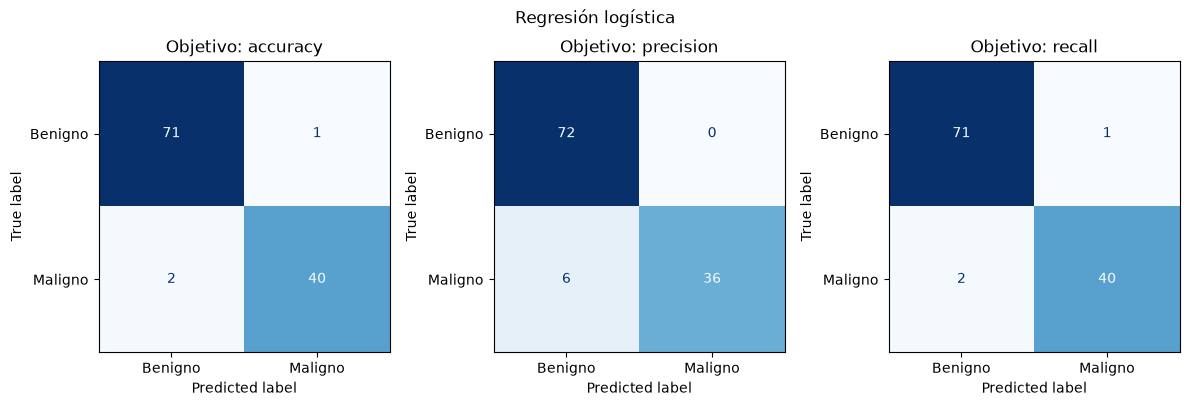

In [17]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))      # 1 fila con 3 recuadros

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('Regresión logística')
plt.tight_layout()
plt.show()

In [18]:
# Guardando como finalista la versión optimizada con recall
finalistas['Regresión logística'] = mejores_modelos['recall']    # ✏️

---
## 6 · Naïve Bayes  *(9 puntos)*

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`var_smoothing`** | Suma una pequeña cantidad a las varianzas para que ninguna sea casi cero. Valores grandes = modelo más "suavizado" | 10 valores entre 10⁻⁹ y 1, generados con `np.logspace(-9, 0, 10)` 🆕 |
| **`priors`** | Probabilidad inicial que el modelo asume para cada clase, en el orden `[benigno, maligno]`. `None` = la proporción de los datos | `None` · `[0.5, 0.5]` · `[0.3, 0.7]` |

<br>

> `np.logspace(-9, 0, 10)` genera 10 números espaciados en potencias de 10: 10⁻⁹, 10⁻⁸, …, 10⁰ = 1. Es muy útil cuando no sabemos ni el orden de magnitud del valor correcto.

In [19]:
# Importando el modelo
from sklearn.naive_bayes import GaussianNB

# Pipeline: escalar → modelo
nb_base = Pipeline([
    ("escalar", StandardScaler()),
    ("modelo",  GaussianNB())    # ✏️
])

# Ajustando el modelo con valores por defecto
nb_base.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


              precision    recall  f1-score   support

     Benigno       0.92      0.96      0.94        72
     Maligno       0.92      0.86      0.89        42

    accuracy                           0.92       114
   macro avg       0.92      0.91      0.91       114
weighted avg       0.92      0.92      0.92       114



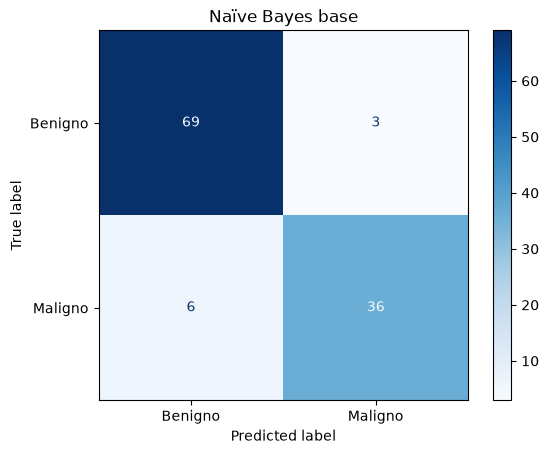

In [20]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = nb_base.predict(X_test)

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))    # ✏️

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')
plt.title('Naïve Bayes base')
plt.show()

In [21]:
# Hiperparámetros a optimizar
rejilla_nb = {
    "modelo__var_smoothing": np.logspace(-9, 0, 10),               # 10 valores: 1e-9, 1e-8, …, 1  ✏️
    "modelo__priors":        [None, [0.5, 0.5], [0.3, 0.7]],        # [benigno, maligno]  ✏️
}
# 10 × 3 = 30 combinaciones

In [22]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(nb_base, rejilla_nb, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.945  {'modelo__priors': [0.5, 0.5], 'modelo__var_smoothing': np.float64(0.1)}
precision >> 0.993  {'modelo__priors': None, 'modelo__var_smoothing': np.float64(1.0)}
recall >> 0.912  {'modelo__priors': [0.3, 0.7], 'modelo__var_smoothing': np.float64(1e-09)}


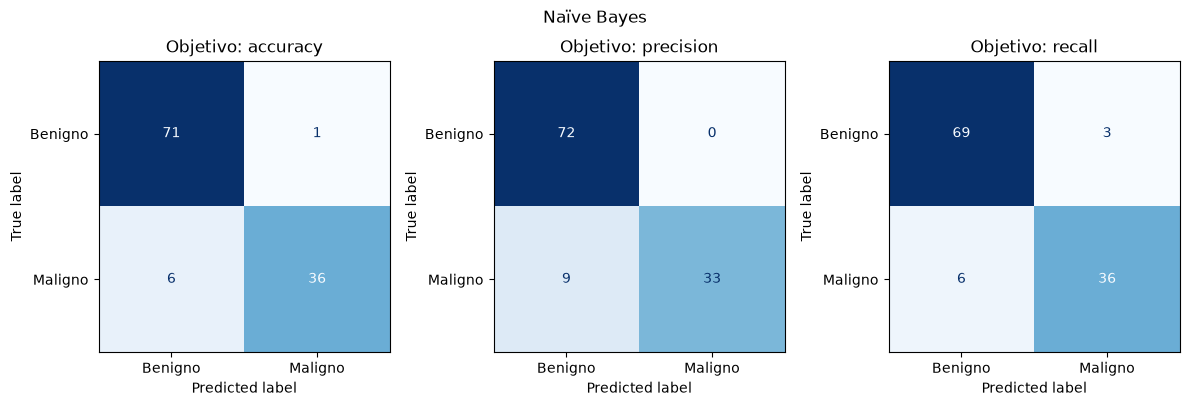

In [23]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('Naïve Bayes')
plt.tight_layout()
plt.show()

In [24]:
# Guardando como finalista la versión optimizada con recall
finalistas['Naïve Bayes'] = mejores_modelos['recall']

---
## 7 · Máquinas de vectores de soporte (SVM)  *(9 puntos)*

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`kernel`** | La forma de la frontera: `"linear"` = recta · `"rbf"` = curvas suaves · `"poly"` 🆕 = curva polinomial | los tres |
| **`C`** | Qué tanto castiga los errores en entrenamiento: `C` grande = frontera más ajustada (riesgo de sobreajuste) | 0.01 · 0.1 · 1 · 10 · 100 |
| **`gamma`** *(solo rbf)* | Qué tan "local" es la influencia de cada paciente | `"scale"` · 0.01 · 0.1 |
| **`degree`** 🆕 *(solo poly)* | Grado del polinomio: 2 = parábola, 3 = cúbica | 2 · 3 |
| **`class_weight`** | `"balanced"` da más peso a los malignos | `None` · `"balanced"` |

Como cada kernel usa hiperparámetros distintos, la rejilla es una **lista de diccionarios** (uno por kernel).

In [25]:
# Importando el modelo
from sklearn.svm import SVC

# Pipeline: escalar → modelo
svm_base = Pipeline([
    ("escalar", StandardScaler()),
    ("modelo",  SVC())    # ✏️
])

# Ajustando el modelo con valores por defecto
svm_base.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


              precision    recall  f1-score   support

     Benigno       0.96      1.00      0.98        72
     Maligno       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



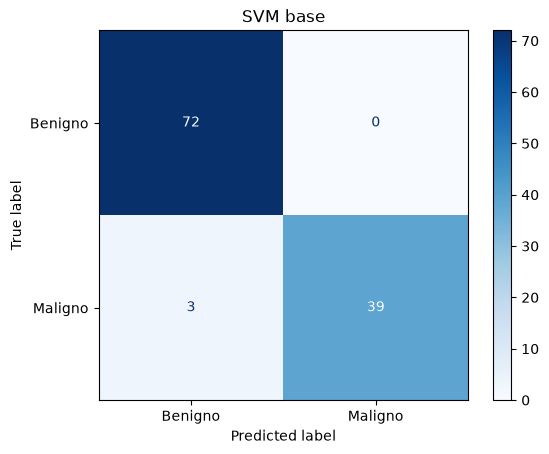

In [26]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = svm_base.predict(X_test)    # ✏️

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')
plt.title('SVM base')
plt.show()

In [27]:
# Hiperparámetros a optimizar
valores_C = [0.01, 0.1, 1, 10, 100]

rejilla_svm = [
    {"modelo__kernel":       ["linear"],
     "modelo__C":            valores_C,
     "modelo__class_weight": [None, "balanced"]},

    {"modelo__kernel":       ["rbf"],    # ✏️
     "modelo__C":            valores_C,
     "modelo__gamma":        ["scale", 0.01, 0.1],
     "modelo__class_weight": [None, "balanced"]},

    {"modelo__kernel":       ["poly"],                    # NUEVO: kernel polinomial
     "modelo__C":            valores_C,
     "modelo__degree":     [2, 3],                      # grado del polinomio  ✏️
     "modelo__class_weight": [None, "balanced"]},
]
# 10 + 30 + 20 = 60 combinaciones

In [28]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(svm_base, rejilla_svm, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.978  {'modelo__C': 10, 'modelo__class_weight': 'balanced', 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}
precision >> 1.000  {'modelo__C': 0.01, 'modelo__class_weight': 'balanced', 'modelo__gamma': 'scale', 'modelo__kernel': 'rbf'}
recall >> 0.959  {'modelo__C': 0.1, 'modelo__class_weight': 'balanced', 'modelo__gamma': 0.1, 'modelo__kernel': 'rbf'}


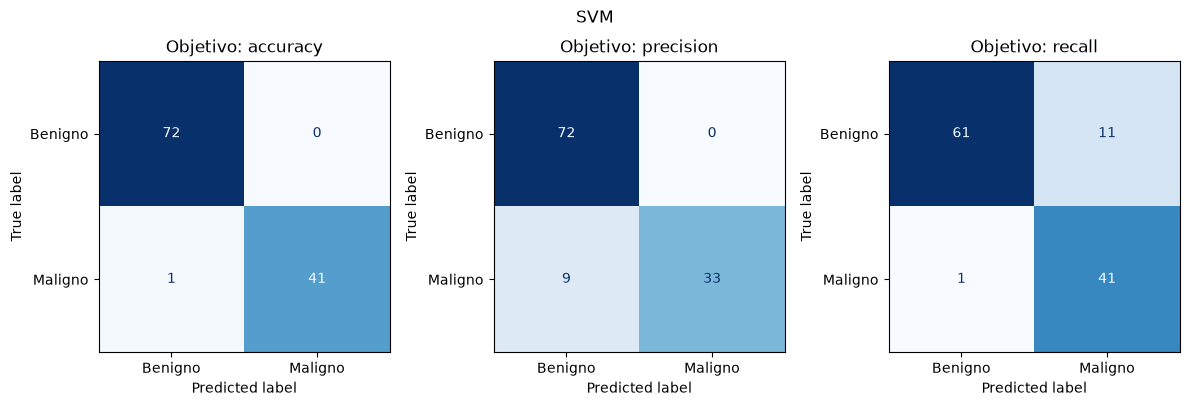

In [29]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('SVM')
plt.tight_layout()
plt.show()

In [30]:
# Guardando como finalista la versión optimizada con recall
finalistas['SVM'] = mejores_modelos['recall']

---
## 8 · Árbol de decisión y Random Forest  *(9 + 9 puntos)*

Los árboles **no necesitan escalar**: solo hacen preguntas del tipo *"¿`perimeter_worst` ≤ 112.8?"*, y la respuesta es la misma en cualquier escala. Por eso aquí **no usamos Pipeline**, y los nombres de la rejilla van **sin** el prefijo `modelo__`.

### 8.1 Árbol de decisión

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`max_depth`** | Cuántas preguntas seguidas puede hacer (los "pisos" del árbol). `None` = sin límite | 2 · 3 · 4 · 5 · 6 · `None` |
| **`min_samples_leaf`** | Mínimo de pacientes en cada hoja | 1 · 5 · 10 |
| **`min_samples_split`** 🆕 | Mínimo de pacientes que debe tener un nodo para **poder dividirse**. Evita preguntas sobre grupos muy pequeños | 2 · 10 · 20 |
| **`criterion`** | Fórmula que mide qué tan "revuelto" queda un grupo | `"gini"` · `"entropy"` |
| **`class_weight`** | `"balanced"` da más peso a los malignos | `None` · `"balanced"` |

In [31]:
# Importando el modelo y la función para dibujarlo
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Creando y ajustando el árbol con valores por defecto (sin Pipeline: no hace falta escalar)
arbol_base = DecisionTreeClassifier(random_state=42)    # ✏️
arbol_base.fit(X_train, y_train)

print('Pisos (profundidad):        ', arbol_base.get_depth())
print('Hojas (decisiones finales): ', arbol_base.get_n_leaves())

Pisos (profundidad):         8
Hojas (decisiones finales):  24


              precision    recall  f1-score   support

     Benigno       0.94      0.94      0.94        72
     Maligno       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



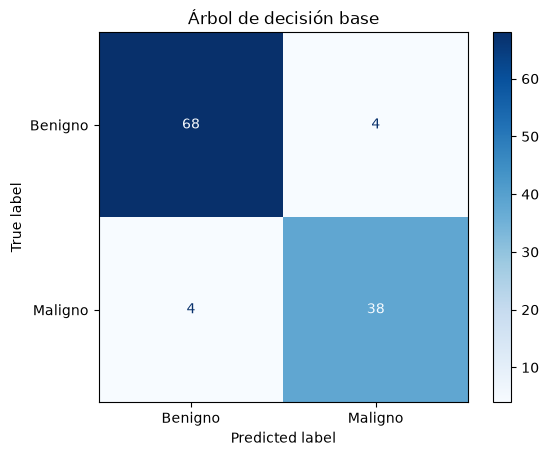

In [32]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = arbol_base.predict(X_test)

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')    # ✏️
plt.title('Árbol de decisión base')
plt.show()

In [33]:
# Hiperparámetros a optimizar (sin el prefijo modelo__ porque no hay Pipeline)
rejilla_arbol = {
    "max_depth":         [2, 3, 4, 5, 6, None],        # None = sin límite
    "min_samples_leaf":  [1, 5, 10],
    "min_samples_split": [2, 10, 20],                  # NUEVO  ✏️
    "criterion":         ["gini", "entropy"],    # ✏️
    "class_weight":      [None, "balanced"],
}
# 6 × 3 × 3 × 2 × 2 = 216 combinaciones (muchas, pero cada árbol tarda milisegundos)

In [34]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(DecisionTreeClassifier(random_state=42), rejilla_arbol, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.938  {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 2}
precision >> 0.940  {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 2}
recall >> 0.929  {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 2}


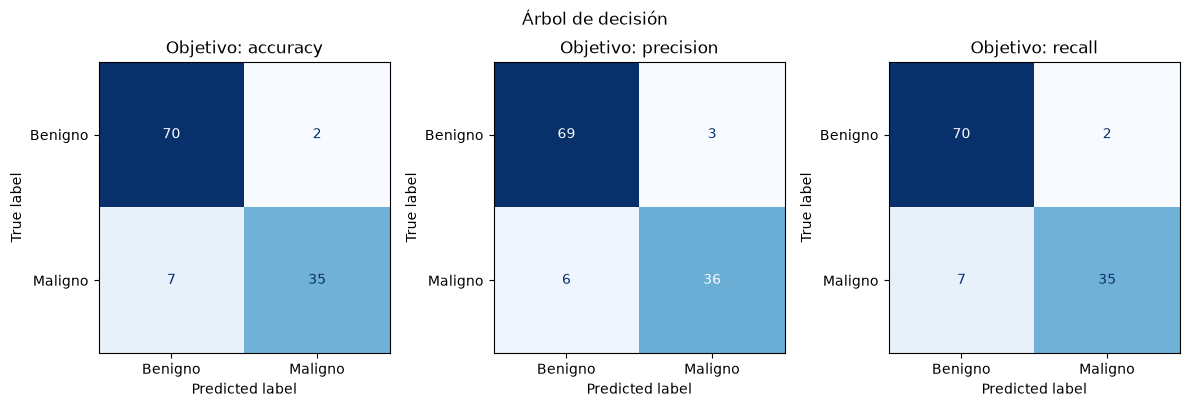

In [35]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('Árbol de decisión')
plt.tight_layout()
plt.show()

In [36]:
# Guardando como finalista la versión optimizada con recall
finalistas['Árbol de decisión'] = mejores_modelos['recall']

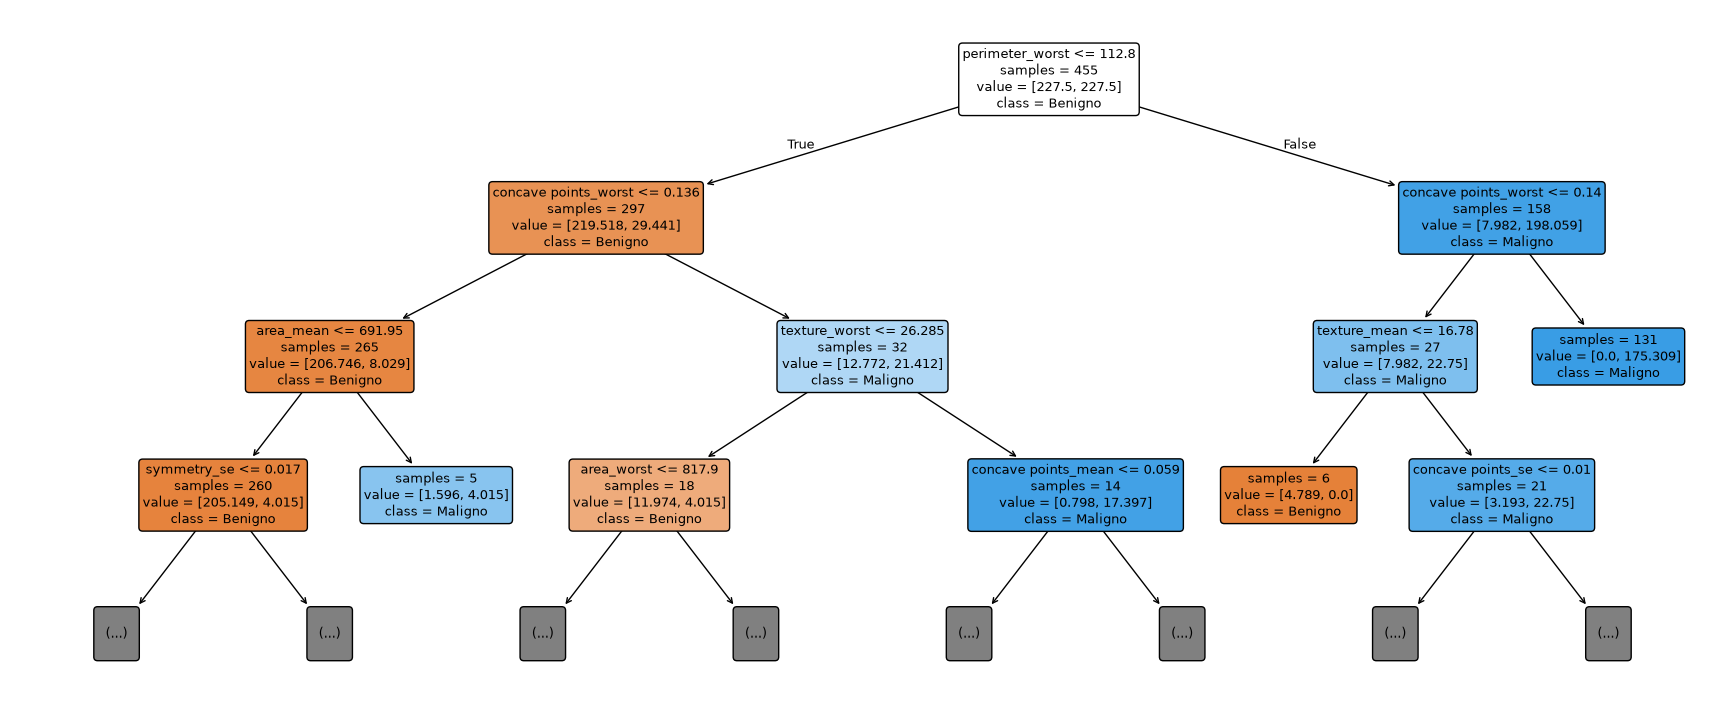

In [37]:
# Dibujando solo los primeros 3 pisos del árbol finalista (completo no cabría en pantalla)
plt.figure(figsize=(22, 9))
plot_tree(finalistas['Árbol de decisión'], feature_names=X.columns, class_names=clases,
          filled=True, rounded=True, impurity=False, max_depth=3, fontsize=9)    # ✏️
plt.show()

> Si el árbol finalista usa `class_weight="balanced"`, los números de `value` son **pacientes ponderados** (cada maligno "vale" más que un benigno), por eso no son enteros. Las cajas **azules** votan *Maligno* y las **naranjas** *Benigno*; entre más intenso el color, más seguro está el árbol.

### 8.2 Random Forest

| Hiperparámetro | Qué controla | Valores que probaremos |
|---|---|---|
| **`n_estimators`** | Cuántos árboles votan | 100 · 300 |
| **`max_features`** | Entre cuántas variables al azar elige cada árbol en cada pregunta. Con 30 variables: `"sqrt"` → 5 · `"log2"` 🆕 → 4 | `"sqrt"` · `"log2"` |
| **`max_depth`** | Igual que en el árbol | 5 · `None` |
| **`min_samples_leaf`** 🆕 | Mínimo de pacientes en cada hoja de cada árbol | 1 · 3 |
| **`class_weight`** | `"balanced"` da más peso a los malignos | `None` · `"balanced"` |

⏱️ Esta búsqueda tarda unos **minutos**: cada combinación entrena cientos de árboles. Ten paciencia.

In [38]:
# Importando el modelo
from sklearn.ensemble import RandomForestClassifier

# Creando y ajustando el bosque con valores por defecto
bosque_base = RandomForestClassifier(random_state=42)    # ✏️
bosque_base.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

              precision    recall  f1-score   support

     Benigno       0.96      1.00      0.98        72
     Maligno       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



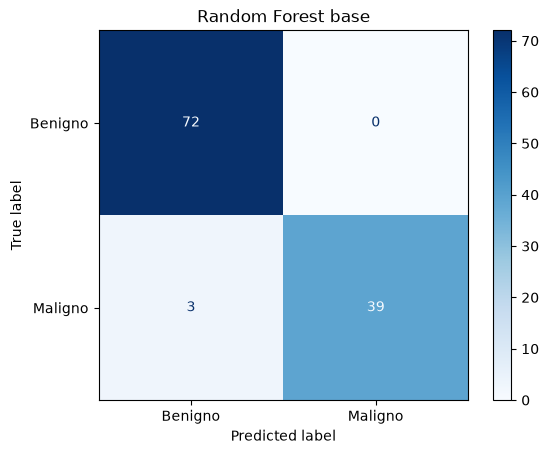

In [39]:
# Calculando las predicciones sobre el conjunto de prueba
y_pred = bosque_base.predict(X_test)

# Imprimiendo el reporte de clasificación
print(classification_report(y_test, y_pred, target_names=clases))    # ✏️

# Construyendo la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases, cmap='Blues')
plt.title('Random Forest base')
plt.show()

In [40]:
# Hiperparámetros a optimizar
rejilla_bosque = {
    "n_estimators":     [100, 300],
    "max_features":     ["sqrt", "log2"],            # NUEVO: 5 o 4 variables al azar  ✏️
    "max_depth":        [5, None],
    "min_samples_leaf": [1, 3],                        # NUEVO  ✏️
    "class_weight":     [None, "balanced"],
}
# 2 × 2 × 2 × 2 × 2 = 32 combinaciones

In [41]:
mejores_modelos = {}

for metrica in metricas:
    busqueda = GridSearchCV(RandomForestClassifier(random_state=42), rejilla_bosque, scoring=metrica, cv=5, n_jobs=-1)    # ✏️
    busqueda.fit(X_train, y_train)
    mejores_modelos[metrica] = busqueda.best_estimator_
    print(f'{metrica} >> {busqueda.best_score_:.3f}  {busqueda.best_params_}')

accuracy >> 0.965  {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}
precision >> 0.959  {'class_weight': None, 'max_depth': 5, 'max_features': 'log2', 'min_samples_leaf': 1, 'n_estimators': 300}
recall >> 0.959  {'class_weight': 'balanced', 'max_depth': 5, 'max_features': 'log2', 'min_samples_leaf': 3, 'n_estimators': 100}


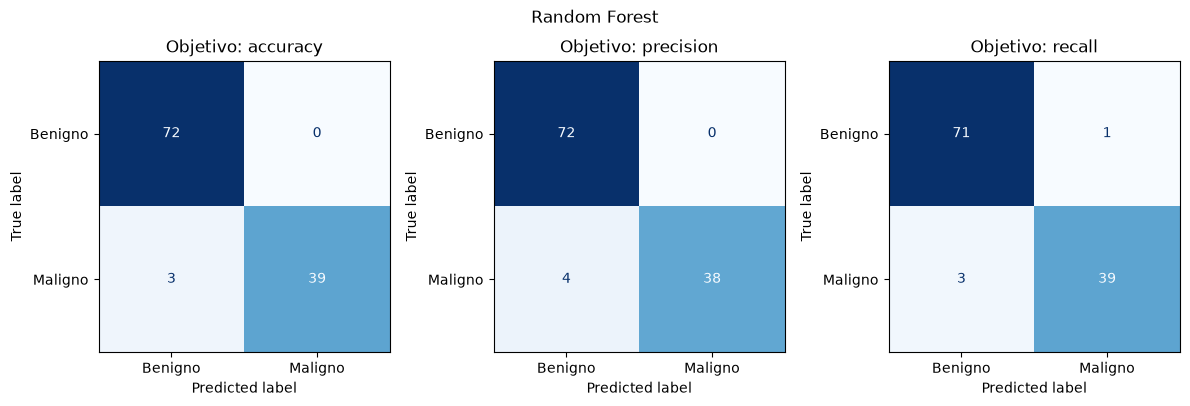

In [42]:
# Mostrando las matrices de confusión de las 3 versiones optimizadas
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    y_pred = mejores_modelos[metrica].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=clases,
                                            cmap='Blues', colorbar=False, ax=eje)
    eje.set_title(f'Objetivo: {metrica}')

plt.suptitle('Random Forest')
plt.tight_layout()
plt.show()

In [43]:
# Guardando como finalista la versión optimizada con recall
finalistas['Random Forest'] = mejores_modelos['recall']

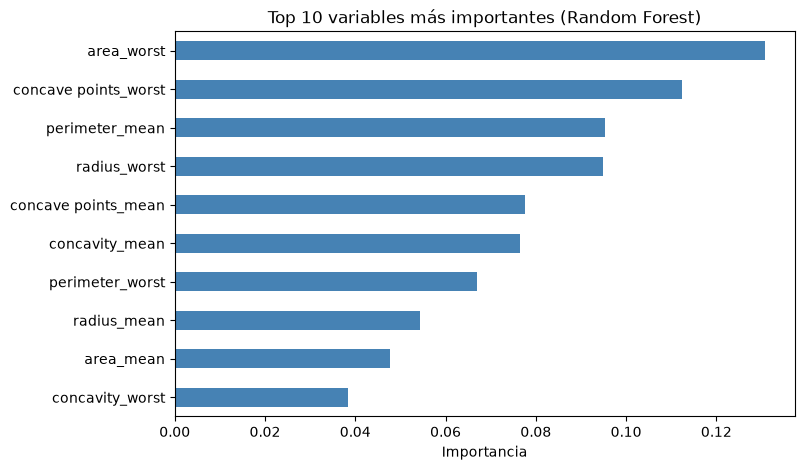

In [44]:
# ¿Qué mediciones usó más el bosque para decidir?
importancias = pd.Series(finalistas['Random Forest'].feature_importances_, index=X.columns)    # ✏️

importancias.sort_values().tail(10).plot.barh(figsize=(8, 5), color='steelblue')
plt.title('Top 10 variables más importantes (Random Forest)')
plt.xlabel('Importancia')
plt.show()

---
## 9 · Comparación final de los cinco finalistas  *(5 puntos)*

Ahora comparamos los 5 finalistas **con los mismos pacientes de prueba**. Completa las fórmulas de sensibilidad y especificidad usando VP, VN, FP y FN.

La tabla queda ordenada de **menos FN a más FN** (y, si hay empate, de menos FP a más FP).

In [45]:
filas = []

for nombre, modelo in finalistas.items():
    y_pred = modelo.predict(X_test)
    vn, fp, fn, vp = confusion_matrix(y_test, y_pred).ravel()      # los 4 números de la matriz
    filas.append({
        'Modelo':        nombre,
        'Exactitud':     (vp + vn) / len(y_test),
        'Sensibilidad':  vp / (vp + fn),             # de los malignos, ¿cuántos detecta?  ✏️
        'Especificidad': vn / (vn + fp),             # de los benignos, ¿cuántos descarta bien?  ✏️
        'FN':            fn,
        'FP':            fp,
    })

tabla = pd.DataFrame(filas).sort_values(by=['FN', 'FP'])
tabla.round(3)

,Modelo,Exactitud,Sensibilidad,Especificidad,FN,FP
2,SVM,0.895,0.976,0.847,1,11
0,Regresión logística,0.974,0.952,0.986,2,1
4,Random Forest,0.965,0.929,0.986,3,1
1,Naïve Bayes,0.921,0.857,0.958,6,3
3,Árbol de decisión,0.921,0.833,0.972,7,2


---
## 10 · Ajuste del umbral de decisión  *(5 puntos)*

Por defecto, los modelos dicen **"Maligno"** cuando la probabilidad de maligno es **≥ 0.5**. Si **bajamos el umbral**, el modelo se vuelve más "desconfiado": detecta más malignos (**menos FN**), a cambio de más falsas alarmas (**más FP**).

Lo probaremos con la **regresión logística** y el **Random Forest**, que calculan probabilidades con `predict_proba`. (La SVM no las calcula por defecto.)

In [47]:
umbrales = [0.5, 0.4, 0.3, 0.2, 0.1]

for nombre in ['Regresión logística', 'Random Forest']:
    proba = finalistas[nombre].predict_proba(X_test)[:, 1]      # columna 1 = probabilidad de "Maligno"  ✏️
    print(nombre)

    for umbral in umbrales:
        y_pred_u = (proba >= umbral).astype(int)                # 1 si supera el umbral, 0 si no  ✏️
        vn, fp, fn, vp = confusion_matrix(y_test, y_pred_u).ravel()
        print(f'   umbral {umbral}:   FN = {fn}   FP = {fp}')
    print()

Regresión logística
   umbral 0.5:   FN = 2   FP = 1
   umbral 0.4:   FN = 1   FP = 1
   umbral 0.3:   FN = 1   FP = 2
   umbral 0.2:   FN = 1   FP = 4
   umbral 0.1:   FN = 0   FP = 9

Random Forest
   umbral 0.5:   FN = 3   FP = 1
   umbral 0.4:   FN = 3   FP = 2
   umbral 0.3:   FN = 1   FP = 3
   umbral 0.2:   FN = 0   FP = 10
   umbral 0.1:   FN = 0   FP = 16



---
## 11 · Reflexión: ¿cuál es el mejor modelo?  *(30 puntos)*

Responde con tus propias palabras y **apóyate en los números** que obtuviste (matrices, tabla de la sección 9 y umbrales de la sección 10). No basta con decir "es mejor": explica **por qué**.

**Pregunta 1 · Falsos negativos vs. falsos positivos** *(7 pts)*
En este problema, ¿qué significa clínicamente un **falso negativo**? Describe qué le pasaría a esa paciente y compáralo con lo que le pasaría a una paciente con un **falso positivo**. ¿Cuál de los dos errores es más costoso y por qué?

✍️ **Tu respuesta:**

Un falso negativo envía a una paciente con cáncer a casa sin tratamiento, lo cual es muy grave y un falso positivo solo causa una falsa alarma y estudios de más, el falso negativo es el error más grande o costoso porque pone en riesgo la vida.

**Pregunta 2 · ¿Con qué métrica optimizar?** *(6 pts)*
Elige uno de los modelos y compara sus matrices de confusión con objetivo `precision` y con objetivo `recall`. ¿Qué pasó con los FN y con los FP? ¿Por qué optimizar la precisión **no** es buena idea en este contexto?

✍️ **Tu respuesta:**

Optimizar la precisión busca evitar falsas alarmas, pero al hacerlo deja escapar muchos tumores malignos (aumentan los FN)

**Pregunta 3 · El mejor modelo** *(10 pts)*
Con la tabla de la sección 9, ¿cuál fue tu **mejor modelo**? Justifica tu elección con **al menos tres números** (FN, FP, sensibilidad, especificidad…). Si dos modelos empataron en FN, explica cómo desempataste.

✍️ **Tu respuesta:**

SVM es el mejor para minimizar riesgos al lograr la menor cantidad de tumores sin detectar (FN = 1, sensibilidad 0.976), aunque genera más falsas alarmas (FP = 11) aunque también esta el de Regresión logística ofrece el mejor balance general con (FN = 2, alta exactitud 0.974 y FP = 1) solo no se que tenga mas importancia si un falso negativo o el que parece mejor o con menores fallas

**Pregunta 4 · ¿Por qué no basta la exactitud?** *(3 pts)*
¿Por qué la exactitud por sí sola no es suficiente para elegir el modelo en este problema? *Pista:* piensa en la proporción de benignos y malignos, y en qué te dice (o no) la exactitud sobre el **tipo** de error.

✍️ **Tu respuesta:**

La exactitud solo mide el total de aciertos globales, pero oculta si los errores son falsas alarmas o tumores malignos no detectados y esto en medicina es peligroso, ya que una alta exactitud puede esconder pacientes enfermos enviados a casa sin tratamiento

**Pregunta 5 · Umbral y uso real** *(4 pts)*
Según la sección 10, ¿qué umbral recomendarías y cuántos FN y FP tendrías con él? ¿Usarías este modelo para **reemplazar** al patólogo o solo como **apoyo**? Menciona una limitación de este estudio.

✍️ **Tu respuesta:**

Recomendaría bajar el umbral (por ejemplo a 0.2 o 0.1) para asegurar cero falsos negativos, este modelo debe usarse únicamente como apoyo para el patólogo, nunca como reemplazo y su limitación es que depende de la calidad de la imagen digitalizada